# 02 · Early-life features

**Goal for week 2:** turn each of the 124 cells into one row of 12 features computed from cycles 1–100 only, saved as `data/processed/features.csv`. Week 3 fits models on this table.

The features follow Severson et al. (2019) and were first built in the Chapter 2 drills. This notebook moves them into the project repo (`src/features.py`), documents one important data-cleaning step, and checks how the features relate to cycle life and to each other.

| Group | Features |
|---|---|
| ΔQ₁₀₀₋₁₀(V) shape | `log_var_dq`, `log_abs_min_dq`, `log_abs_skew_dq`, `log_abs_kurt_dq` |
| Capacity fade (cycles 2–100) | `qd_cycle2`, `qd_max_minus_cycle2`, `fade_slope`, `fade_intercept` |
| Charging, temperature, resistance | `charge_time_2to6`, `temp_max`, `ir_min`, `ir_change_2to100` |

**Rule for every check below:** statistics that could influence modelling choices (correlations, scaling) use the **41 training cells only**. Test cells are only looked at for data-quality checks.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.load_data import load_cells, split_keys
from src.features import (FEATURE_COLUMNS, build_feature_table, despike,
                          load_feature_table)

PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
FEATURES_CSV = PROCESSED / "features.csv"
SPLIT_COLOURS = {"train": "C0", "test": "C1", "secondary_test": "C2"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1 · Load the cleaned cells

In [2]:
cells = load_cells(PROCESSED)
splits = split_keys(cells)
assert len(cells) == 124, "Expected 124 cells after cleaning"
print({name: len(keys) for name, keys in splits.items()})

{'train': 41, 'test': 43, 'secondary_test': 40}


## 2 · Why the summary data needs despiking

The per-cycle summary arrays (`QD`, `IR`) contain one-cycle logging spikes. On the first run of the drills, a single spike made `qd_max_minus_cycle2` hundreds of standard deviations out for two cells, and linear regression extrapolated them to predicted lives of about 10¹⁹ and 3×10⁷ cycles.

The fix is a 5-cycle rolling median (`despike`): it removes isolated spikes but keeps real trends, because a genuine change lasts more than two cycles.

In [3]:
def qd_max_minus_cycle2(cell, clean):
    qd = np.asarray(cell["summary"]["QD"][1:100], dtype=float)
    if clean:
        qd = despike(qd)
    return qd.max() - qd[0]

compare = pd.DataFrame({
    "raw": {k: qd_max_minus_cycle2(c, clean=False) for k, c in cells.items()},
    "despiked": {k: qd_max_minus_cycle2(c, clean=True) for k, c in cells.items()},
})
# Express each version in training standard deviations from the training mean
train = compare.loc[splits["train"]]
z = (compare - train.mean()) / train.std()
z.columns = ["raw (σ from train mean)", "despiked (σ)"]
z.reindex(z.iloc[:, 0].abs().sort_values(ascending=False).index).head(6).round(1)

,raw (σ from train mean),despiked (σ)
b1c18,886.1,-0.3
b1c0,226.3,0.8
b2c17,2.8,1.8
b3c6,-2.4,-2.3
b3c28,-2.2,-2.1
b3c21,-2.2,-2.0


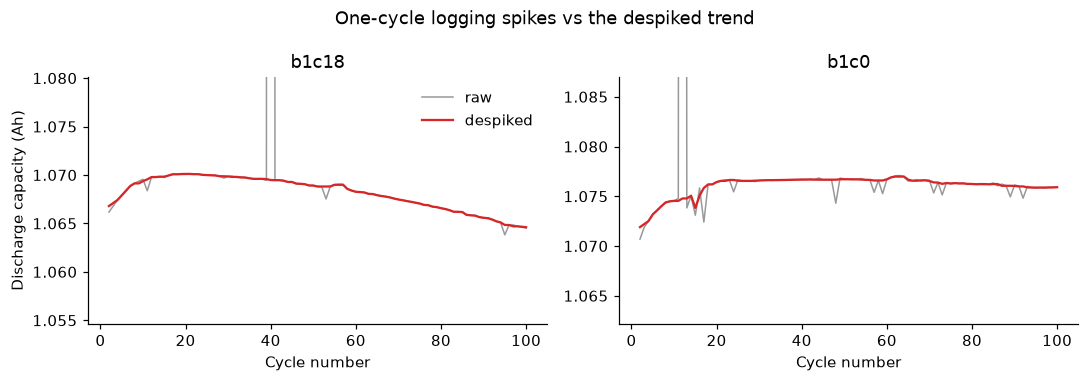

In [4]:
# Show the two worst cells' raw and despiked capacity
worst = z.iloc[:, 0].abs().sort_values(ascending=False).index[:2]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
cycles = np.arange(2, 101)
for ax, key in zip(axes, worst):
    qd = np.asarray(cells[key]["summary"]["QD"][1:100], dtype=float)
    ax.plot(cycles, qd, color="0.6", lw=1, label="raw")
    ax.plot(cycles, despike(qd), color="C3", lw=1.5, label="despiked")
    lo, hi = np.percentile(despike(qd), [1, 99])
    ax.set_ylim(lo - 0.01, hi + 0.01)  # zoom to the real data; spikes run off the axis
    ax.set_title(key)
    ax.set_xlabel("Cycle number")
axes[0].set_ylabel("Discharge capacity (Ah)")
axes[0].legend(frameon=False)
fig.suptitle("One-cycle logging spikes vs the despiked trend")
fig.tight_layout()
fig.savefig(FIGURES / "02_despike_examples.png", dpi=200)

*Notes:*

The spiky cells (b1c18, b1c0) were both in the test set, so grouped CV on the 41 training cells never saw them. CV only tells you how a model performs on data similar to its training data; it can’t detect corrupted or out-of-range inputs elsewhere. Lesson: check every input before predicting (e.g. flag any feature more than a few σ outside the training range), separately from CV. The same idea applies to batch 3’s domain shift.

## 3 · Build the feature table and check it

If a `features.csv` already exists, this compares against it before overwriting, so you know the move into `src/features.py` changed nothing.

In [5]:
features = build_feature_table(cells, splits)
print(features.shape, "| missing values:", int(features[FEATURE_COLUMNS].isna().sum().sum()))

if FEATURES_CSV.exists():
    old = load_feature_table(FEATURES_CSV)
    same_rows = old.index.equals(features.index)
    num_cols = FEATURE_COLUMNS + ["cycle_life"]
    max_diff = (old[num_cols] - features[num_cols]).abs().max()
    matches = same_rows and np.allclose(old[num_cols], features[num_cols], equal_nan=True)
    print("Matches the drills' features.csv:", matches)
    if not matches:
        print(max_diff[max_diff > 0])
        features.to_csv(PROCESSED / "features_new.csv")
        print("Saved to features_new.csv instead. Investigate before replacing features.csv.")
    else:
        features.to_csv(FEATURES_CSV)
else:
    features.to_csv(FEATURES_CSV)
    print("Saved", FEATURES_CSV)

features[FEATURE_COLUMNS].describe().T.round(4)

(124, 16) | missing values: 0
Matches the drills' features.csv: True


,count,mean,std,min,25%,50%,75%,max
log_var_dq,124.0,-3.8364,0.4126,-5.0149,-4.1150,-3.7752,-3.5261,-2.7269
log_abs_min_dq,124.0,-1.4350,0.2046,-2.0726,-1.5734,-1.4117,-1.2832,-0.8600
log_abs_skew_dq,124.0,-0.7946,0.4116,-2.3378,-1.0075,-0.7225,-0.4808,0.0335
log_abs_kurt_dq,124.0,0.0727,0.0748,-0.4576,0.0559,0.0929,0.1105,0.1421
qd_cycle2,124.0,1.0721,0.0095,1.0438,1.0679,1.0724,1.0790,1.0959
qd_max_minus_cycle2,124.0,0.0034,0.0015,0.0000,0.0023,0.0032,0.0044,0.0075
fade_slope,124.0,-0.0000,0.0001,-0.0011,-0.0000,-0.0000,0.0000,0.0000
fade_intercept,124.0,1.0752,0.0096,1.0495,1.0706,1.0755,1.0822,1.0985
charge_time_2to6,124.0,10.4250,0.7436,8.9647,10.0438,10.1297,10.2852,13.4092
temp_max,124.0,37.3165,1.7457,31.6589,36.2521,37.5601,38.4868,40.1955


In [6]:
features.loc[["b1c18", "b1c0"], "split"]

cell
b1c18    test
b1c0     test
Name: split, dtype: str

In [7]:
z = (features[FEATURE_COLUMNS] - features[FEATURE_COLUMNS].mean()) / features[FEATURE_COLUMNS].std()
flags = z.abs().stack()
flags = flags[flags > 4].sort_values(ascending=False)
flags.to_frame("|z|").join(features[["split", "charge_policy", "cycle_life"]], on=flags.index.get_level_values(0))

,,key_0,|z|,split,charge_policy,cycle_life
cell,,,,,,
b2c1,fade_slope,b2c1,9.430890,test,2C(10%)-6C,148.0
b1c18,ir_change_2to100,b1c18,8.894554,test,5.4C(70%)-3C,691.0
b1c2,log_abs_kurt_dq,b1c2,7.088733,test,3.6C(80%)-3.6C,2237.0
b2c1,log_abs_kurt_dq,b2c1,4.887053,test,2C(10%)-6C,148.0
b1c1,charge_time_2to6,b1c1,4.012915,train,3.6C(80%)-3.6C,2160.0


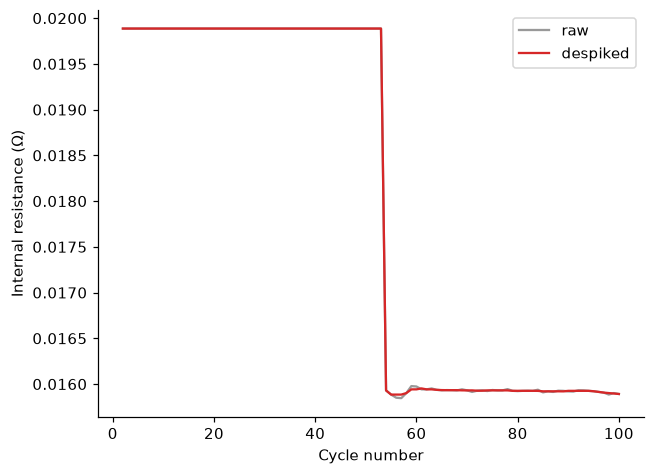

In [8]:
ir = np.asarray(cells["b1c18"]["summary"]["IR"][1:100], dtype=float)
plt.plot(range(2, 101), ir, color="0.6", label="raw")
plt.plot(range(2, 101), despike(ir), color="C3", label="despiked")
plt.xlabel("Cycle number"); plt.ylabel("Internal resistance (Ω)"); plt.legend()

Five feature values exceed 4σ across four cells. Four are physically real extremes: b2c1 (148 cycles) has the steepest fade and most distorted ΔQ shape; b1c1 has a long charge time from a gentle 3.6C policy; b1c2 (2,237 cycles) has extreme ΔQ kurtosis because its near-flat ΔQ curve is mostly noise, so kurtosis is unreliable for long-lived cells. One looks like a data error: b1c18 shows a large IR drop over cycles 2–100, against normal ageing, on an ordinary cell that also had QD spikes. [Add what the IR plot shows.] Lesson: outlier ≠ error; check each against the physics.

In [9]:
def longest_flat_run(x):
    x = np.asarray(x, dtype=float)
    same = np.r_[False, np.diff(x) == 0]
    runs, best = 0, 0
    for s in same:
        runs = runs + 1 if s else 0
        best = max(best, runs)
    return best + 1 if best else 0

flat = pd.DataFrame({
    "IR_flat_run": {k: longest_flat_run(c["summary"]["IR"][1:100]) for k, c in cells.items()},
    "QD_flat_run": {k: longest_flat_run(c["summary"]["QD"][1:100]) for k, c in cells.items()},
}).join(features["split"])
flat[(flat.IR_flat_run >= 10) | (flat.QD_flat_run >= 10)]

,IR_flat_run,QD_flat_run,split
b1c18,52,0,test


b1c18’s IR is perfectly constant at 0.0199 Ω for cycles 2–53 (no measurement noise, so a stuck or placeholder reading), then drops to a normal ~0.0159 Ω. Its ir_change_2to100 (−0.004 Ω, 8.9σ) is therefore an artefact. Despike can’t remove it because a 5-cycle median follows a 50-cycle plateau. b1c18 is a test cell, so training is unaffected, but its IR change should be treated as missing. Second lesson: despiking handles short spikes, not long flat-lines; data-quality checks need both.

## 4 · Which features track cycle life? (training cells only)

Pearson correlation of each feature with log₁₀ cycle life.

log_var_dq            -0.90
log_abs_min_dq        -0.89
charge_time_2to6       0.77
ir_change_2to100       0.42
ir_min                -0.41
fade_slope             0.40
log_abs_skew_dq        0.38
temp_max              -0.34
qd_cycle2              0.31
fade_intercept         0.28
log_abs_kurt_dq       -0.16
qd_max_minus_cycle2    0.14
dtype: float64

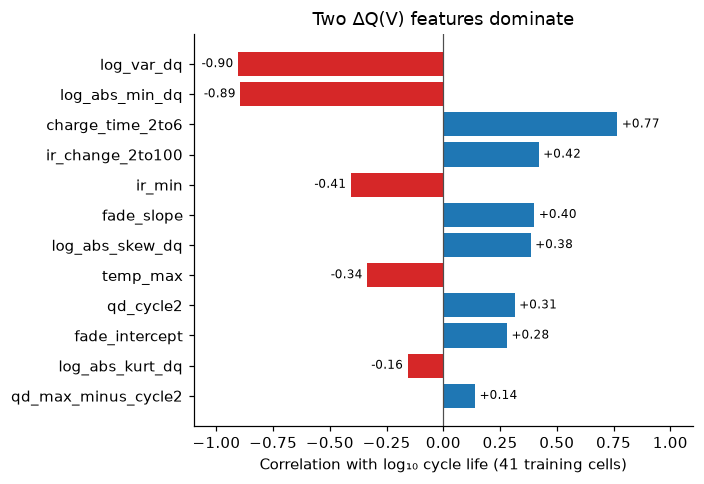

In [10]:
tr = features.loc[splits["train"]]
log_life = np.log10(tr["cycle_life"])
corr = tr[FEATURE_COLUMNS].corrwith(log_life).sort_values(key=np.abs)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(corr.index, corr.values, color=["C3" if r < 0 else "C0" for r in corr.values])
ax.axvline(0, color="0.3", lw=0.8)
for y_pos, r in enumerate(corr.values):
    ax.text(r + (0.02 if r >= 0 else -0.02), y_pos, f"{r:+.2f}", va="center",
            ha="left" if r >= 0 else "right", fontsize=8)
ax.set_xlim(-1.1, 1.1)
ax.set_xlabel("Correlation with log₁₀ cycle life (41 training cells)")
ax.set_title("Two ΔQ(V) features dominate")
fig.tight_layout()
fig.savefig(FIGURES / "02_feature_correlations.png", dpi=200)
corr.sort_values(key=np.abs, ascending=False).round(2)

## 5 · The strongest features against cycle life

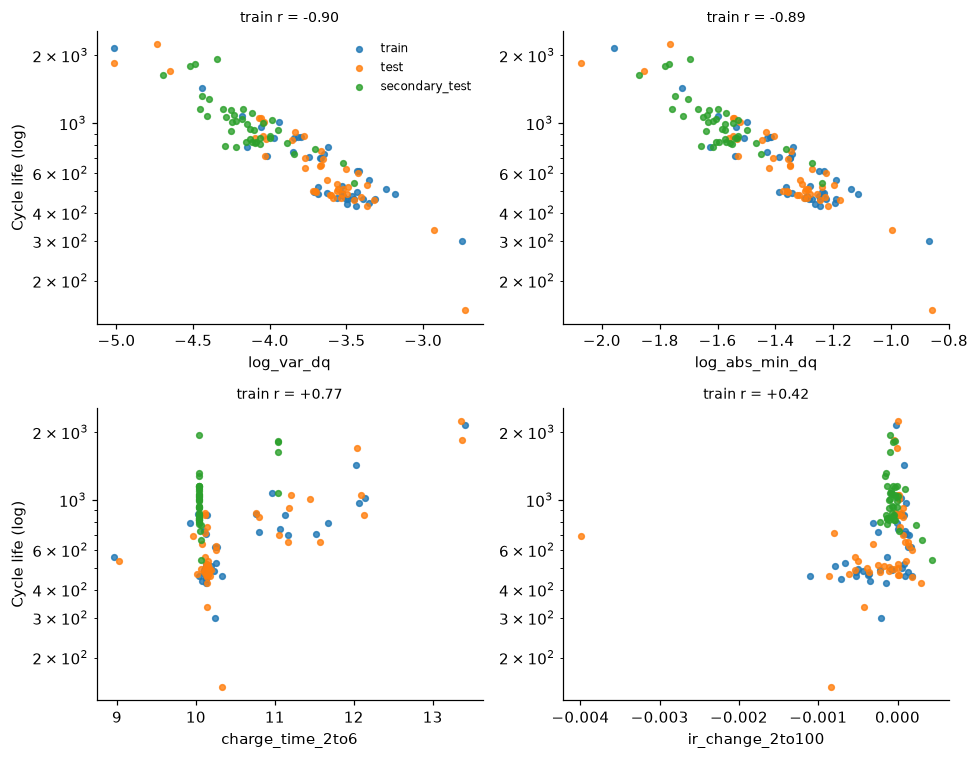

In [11]:
top4 = corr.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, feat in zip(axes.flat, top4):
    for split, colour in SPLIT_COLOURS.items():
        sub = features.loc[splits[split]]
        ax.scatter(sub[feat], sub["cycle_life"], s=14, color=colour, label=split, alpha=0.8)
    ax.set_yscale("log")
    ax.set_xlabel(feat)
    ax.set_title(f"train r = {corr[feat]:+.2f}", fontsize=9)
axes[0, 0].set_ylabel("Cycle life (log)")
axes[1, 0].set_ylabel("Cycle life (log)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "02_top_features.png", dpi=200)

Charge_time_2to6 is a disguised label for the charging policy, not a measurement of the cell’s condition. The fast 0–80% step is fixed by the policy, so charge time mostly records how aggressive the protocol was (more aggressive means shorter life, which is already known). Evidence: a vertical column of cells at ~10 min (nearly all of batch 3, plus many b1/b2) spans lives of ~300–2,000 cycles, so the feature carries no information within it; the +0.77 comes from the few cells on noticeably gentler or harsher policies. Implication: it may help on the primary test set (shared policies) but not on batch 3 (identical charge times). Test in week 3: compare models with and without it.

## 6 · Which features carry the same information?

Correlations *between* features (training cells). Pairs close to ±1 are near-duplicates. Ordinary linear regression becomes unstable with near-duplicate inputs, which is what regularisation (ridge, lasso) is for.

log_var_dq           log_abs_min_dq      1.00
qd_cycle2            fade_intercept      0.99
log_var_dq           charge_time_2to6   -0.77
log_abs_min_dq       charge_time_2to6   -0.75
log_abs_kurt_dq      fade_slope          0.73
qd_max_minus_cycle2  fade_slope          0.66
dtype: float64

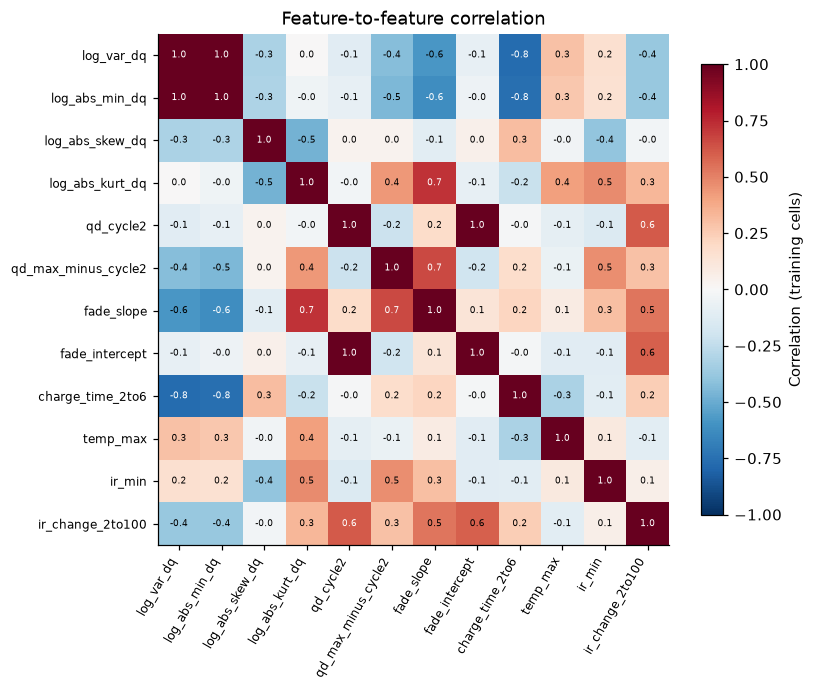

In [12]:
fc = tr[FEATURE_COLUMNS].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(fc, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, fontsize=8)
for i in range(len(FEATURE_COLUMNS)):
    for j in range(len(FEATURE_COLUMNS)):
        ax.text(j, i, f"{fc.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6,
                color="white" if abs(fc.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation (training cells)")
ax.set_title("Feature-to-feature correlation")
fig.tight_layout()
fig.savefig(FIGURES / "02_feature_redundancy.png", dpi=200)

pairs = fc.where(np.triu(np.ones(fc.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(2)

slope = 2.05  (theory: about 2)


Text(0, 0.5, 'log var ΔQ')

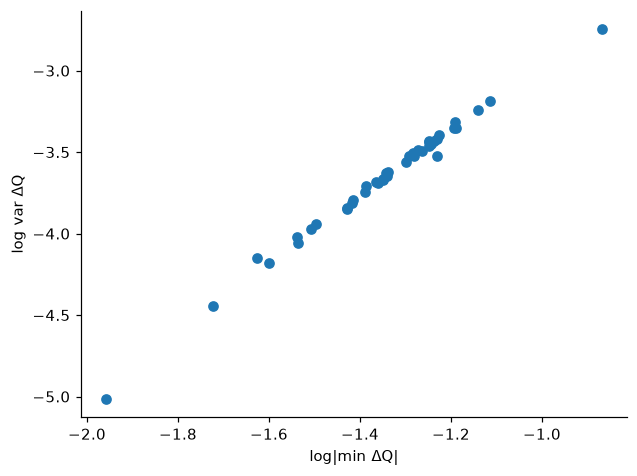

In [13]:
slope, intercept = np.polyfit(tr["log_abs_min_dq"], tr["log_var_dq"], 1)
print(f"slope = {slope:.2f}  (theory: about 2)")
plt.scatter(tr["log_abs_min_dq"], tr["log_var_dq"]); plt.xlabel("log|min ΔQ|"); plt.ylabel("log var ΔQ")

the minimum scales with depth: |min| = a·|min f|, so log|min| = log a + constant;

the variance scales with depth squared: var = a²·var(f), so log var = 2 log a + constant.

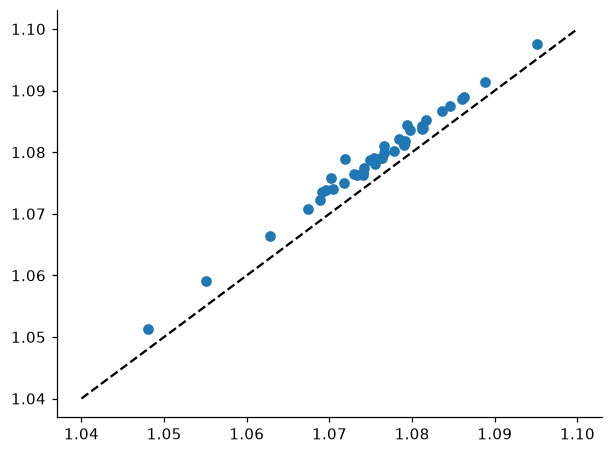

In [15]:
plt.scatter(tr["qd_cycle2"], tr["fade_intercept"]); plt.plot([1.04, 1.10], [1.04, 1.10], "k--")

fade_intercept is where the fitted capacity line hits cycle 0. Because capacity barely changes over 100 cycles (fade of order 0.0005 Ah), that line is almost flat, so its intercept is essentially the starting capacity, which is qd_cycle2. Meanwhile, starting capacities differ between cells by about 0.01 Ah (the standard deviation in the table), 20 times more than the fade. So both features are dominated by “how big was this cell to begin with”, and they move together.

Near-duplicates: (1) log_var_dq ↔ log_abs_min_dq, r = 1.00: both summarise the same ΔQ(V) dip, which has a common shape across cells and differs mainly in depth a. log|min| ∝ log a and log var ∝ 2 log a, so they’re linear in each other (fitted slope ≈ [fill in], theory 2). (2) qd_cycle2 ↔ fade_intercept, r = 0.99: fade over 100 cycles (~0.0005 Ah) is tiny compared with cell-to-cell differences in starting capacity (~0.01 Ah), so the line’s intercept ≈ starting capacity. Not duplicates but a shared cause: charge_time_2to6 ↔ ΔQ features (r ≈ −0.77), because aggressive policies both shorten charge time and accelerate degradation. Implication: effectively 10 independent features, not 12; use ridge/lasso in week 3 or keep one of each pair.

## 7 · Do the batches look different? (domain shift)

Each feature standardised by the **training** mean and standard deviation, then averaged per batch. Training cells come only from batches 1 and 2, so a batch 3 value far from 0 means the model will meet inputs unlike anything it learned from.

In [16]:
mu, sd = tr[FEATURE_COLUMNS].mean(), tr[FEATURE_COLUMNS].std()
z_feat = (features[FEATURE_COLUMNS] - mu) / sd
shift = z_feat.groupby(features["batch"]).mean().T
shift["b3 − b1/b2 (σ)"] = shift["b3"] - shift[["b1", "b2"]].mean(axis=1)
shift.reindex(shift["b3 − b1/b2 (σ)"].abs().sort_values(ascending=False).index).round(2)

batch,b1,b2,b3,b3 − b1/b2 (σ)
ir_min,-0.55,0.69,-2.09,-2.16
fade_intercept,0.36,-0.31,-1.51,-1.54
qd_cycle2,0.40,-0.37,-1.33,-1.35
log_abs_min_dq,-0.68,0.50,-1.36,-1.27
log_var_dq,-0.68,0.49,-1.32,-1.23
qd_max_minus_cycle2,-0.06,0.11,-0.83,-0.85
log_abs_kurt_dq,-0.29,-0.21,-0.99,-0.75
charge_time_2to6,0.57,-0.48,-0.48,-0.53
ir_change_2to100,0.20,-0.43,0.35,0.46
log_abs_skew_dq,0.40,-0.18,0.41,0.30


Batch 3 differs most on ir_min (−2.2σ, lower resistance), starting capacity (qd_cycle2/fade_intercept ≈ −1.4σ, lower) and ΔQ features (≈ −1.3σ, less early change), with temp_max unchanged. Low IR + low capacity at the same temperature points to a different cell lot or measurement set-up (the “newstructure” protocol), i.e. a batch effect rather than ageing. The shifts pull in opposite directions: smaller ΔQ and lower IR push predicted life up (consistent with batch 3’s genuinely longer lives), while lower capacity and shorter charge time push it down. The −11% under-prediction suggests the downward features dominate, plus extrapolation beyond the training range of ΔQ. Batch effects exist within training too (ir_min: b1 −0.55σ vs b2 +0.69σ).

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

lin = make_pipeline(StandardScaler(), LinearRegression())
lin.fit(tr[FEATURE_COLUMNS], np.log10(tr["cycle_life"]))
coef = pd.Series(lin[-1].coef_, index=FEATURE_COLUMNS)   # log10-life per training σ
contrib = (coef * shift["b3"]).sort_values()
print(contrib.round(3))
print("Net effect on log10 life:", round(contrib.sum(), 3))

qd_cycle2             -0.321
log_abs_kurt_dq       -0.028
charge_time_2to6      -0.017
qd_max_minus_cycle2   -0.013
fade_slope            -0.004
ir_change_2to100      -0.002
temp_max              -0.001
log_abs_skew_dq        0.003
log_abs_min_dq         0.017
ir_min                 0.072
log_var_dq             0.143
fade_intercept         0.294
dtype: float64
Net effect on log10 life: 0.143


In [18]:
actual_gap = np.log10(features.loc[features["batch"] == "b3", "cycle_life"]).mean() - np.log10(tr["cycle_life"]).mean()
print(f"Actual b3 gap: {actual_gap:.3f}   Predicted gap: {contrib.sum():.3f}")

Actual b3 gap: 0.204   Predicted gap: 0.143


Contribution check (linear model, 12 features): the predicted shift for batch 3 is +0.143 log₁₀ life (≈ 1.4× longer than the training average), driven by log_var_dq (+0.14) and ir_min (+0.07): less early degradation and lower resistance. The twin features qd_cycle2 (−0.32) and fade_intercept (+0.29) get opposite-sign weights and cancel, a live example of near-duplicate instability (section 6), so starting capacity has little net effect. So the −11% under-prediction isn’t from features pulling predictions down: the model correctly shifts batch 3 upwards, but not enough. Actual b3 gap = 0.204 vs predicted 0.143. This is domain shift: for the same features, batch 3 cells live longer than batches 1–2, a relationship the model can’t learn without batch 3 in training. Regularisation (week 3) should stabilise the twin weights but won’t fix the shift.

---
## Week 2 findings

- **Feature table:** 124 cells × 12 early-life features (cycles 1–100 only), saved to `data/processed/features.csv`; no missing values expected.
- **Data quirk:** summary `QD` and `IR` contain one-cycle logging spikes. Unfixed, `qd_max_minus_cycle2` was 886σ (b1c18) and 226σ (b1c0) from the training mean, and linear regression predicted 10¹⁹ and 3×10⁷ cycles. A 5-cycle rolling median fixes it. Grouped CV on the training cells did not catch it.
- **Correlations with log life (train):** `log_var_dq` −0.90, `log_abs_min_dq` −0.89, `charge_time_2to6` +0.77 (likely a proxy for how gentle the charging policy is); all others |r| ≤ 0.42.
- **Preview of week 3 (from the drills):** grouped 5-fold CV by charge policy, log₁₀ MAE: linear regression 0.045 ± 0.013, kNN(3) 0.053 ± 0.029, random forest 0.065 ± 0.036 (overfits). Linear regression on 12 features: 15.2% test, 15.3% secondary.
- **Bias persists with more features:** b1 −0.3%, b2 +9.2%, b3 −11.2%; worst cell still b2c1 (148 → 519). Batch 3 is a domain shift (never in training, revised protocol), which more features or models won't fix.
- **Split caveat:** 22/43 primary test cells share a charge policy with a training cell, 0/40 secondary. Quote the secondary error for "unseen protocol" claims.
- **Redundancy (section 6):** *[fill in]*
- **Batch 3 shift (section 7):** *[fill in]*

**Week 2 done when:** `features.csv` is rebuilt from `src/features.py` and matches the drills' version, the figures are saved, and sections 6–7 have notes. Commit, then tick week 2 off in the plan.